# 02 — Regresioni linear

        **Pyetja udhëheqëse:** Si vlerësojmë një parametër fizik nga matje me zhurmë?

        Ky notebook është ndërtuar si një mësim i plotë kompjuterik. Rruga kryesore ndjek:
        **problem konkret → model matematikor → zbatim nga parimet e para → bibliotekë profesionale → krahasim → interpretim**.

        ## Objektivat
        - Të nxirret zgjidhja e katrorëve më të vegjël.
- Të interpretohen residualet dhe pasiguria.
- Të krahasohet zbatimi manual me `LinearRegression`.
- Të kuptohet kondicionimi numerik.

        > **Rruga bazë për orën mësimore (45–60 min)** shënohet me seksionet **CORE**.  
        > Seksionet **EXTENDED** dhe **PLAYGROUND** janë për thellim dhe punë të pavarur.

## Pse kjo temë është e nevojshme?

Regresioni linear është pika më e natyrshme për të lidhur matjen fizike me vlerësimin statistikor të parametrave. Në vend që ta trajtojmë si një formulë për të vizatuar një vijë, e përdorim si shembull të plotë të kalimit nga ligji fizik te modeli probabilistik, te vlerësimi numerik dhe më pas te analiza e residualeve dhe pacaktueshmërisë.

Qëllimi është të kuptohet pse një koeficient i përshtatjes ka kuptim fizik vetëm kur janë të arsyeshme hipotezat e modelit dhe kur diagnostika nuk tregon strukturë të pambuluar nga modeli.

### Si duhet lexuar ky notebook

Për çdo bllok kodi do të shpjegojmë **pse** kryhet ai hap, çfarë pyetjeje i përgjigjet dhe çfarë duhet të kontrollojmë në dalje. Kodi nuk trajtohet si recetë: çdo grafik dhe çdo metrikë duhet të rikthehet te hipoteza matematikore dhe te interpretimi fizik. Kur një rezultat nuk sillet siç presim, pyetja e parë nuk është “si ta rrisim score-in?”, por “cilën hipotezë të modelit ose të të dhënave po shkelim?”.

### Para se të ekzekutojmë: Mjedisi llogaritës dhe riprodhueshmëria

Ngarkojmë bibliotekat që do të përdoren dhe fiksojmë `RANDOM_STATE = 42`. Ky seed nuk e bën problemin determinist në kuptimin fizik; ai thjesht na lejon të përsërisim të njëjtin eksperiment llogaritës dhe të diskutojmë metodën pa u hutuar nga ndryshime të rastësishme të mostrës.

**Çfarë duhet të vëzhgojmë?** Pas ekzekutimit, kontrolloni jo vetëm vlerën numerike, por edhe nëse drejtimi i ndryshimit, shkalla e madhësive dhe forma e grafikut janë në përputhje me pritshmërinë teorike. Kjo e kthen qelizën nga një komandë programimi në një hap të arsyetimit shkencor.

In [1]:
# Qëllimi i këtij blloku: Mjedisi llogaritës dhe riprodhueshmëria.
# Ngarkojmë vetëm mjetet që duhen për këtë hap të analizës.
import numpy as np
# Ngarkojmë vetëm mjetet që duhen për këtë hap të analizës.
import pandas as pd
# Ngarkojmë vetëm mjetet që duhen për këtë hap të analizës.
import matplotlib.pyplot as plt
# Ngarkojmë vetëm mjetet që duhen për këtë hap të analizës.
from pathlib import Path
# Ngarkojmë vetëm mjetet që duhen për këtë hap të analizës.
import time

RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE)

print("02 — Regresioni linear")
print("Seed:", RANDOM_STATE)

02 — Regresioni linear
Seed: 42


**Pyetje për interpretim.** Çfarë përfundimi lejon ky rezultat dhe çfarë **nuk** lejon të përfundojmë? Nëse do të ndryshonim zhurmën, madhësinë e kampionit ose ndarjen e të dhënave, cilën pjesë të rezultatit prisni të ishte më e ndjeshme?

# 1. Ligji i Hooke-it si problem regresioni — CORE

Për një sustë ideale,
$$
F=kx.
$$
Në matje reale kemi $F_i=kx_i+\epsilon_i$. Në formë matricore, për modelin e përgjithshëm linear,
$$
\mathbf{y}=X\boldsymbol{\beta}+\boldsymbol{\epsilon}.
$$
Zgjedhim $\hat{\beta}$ duke minimizuar
$$
S(\beta)=\|\mathbf{y}-X\beta\|_2^2.
$$
Nga $\nabla_\beta S=0$ merret
$$
X^T X\hat\beta=X^T\mathbf y,
$$
dhe, kur matrica është e invertueshme,
$$
\hat\beta=(X^TX)^{-1}X^T\mathbf y.
$$
Në praktikë preferojmë zgjidhës numerikisht më të qëndrueshëm sesa inversin e drejtpërdrejtë.

### Para se të ekzekutojmë: Gjenerimi i matjeve të ligjit të Hooke-it

Krijojmë një eksperiment ku parametri i kërkuar, konstanta elastike $k$, është i njohur. Shtimi i zhurmës imiton pacaktueshmërinë eksperimentale. Ky konfigurim na lejon të testojmë nëse procedura e regresionit rikuperon parametrin fizik brenda pacaktueshmërisë së pritur.

**Çfarë duhet të vëzhgojmë?** Pas ekzekutimit, kontrolloni jo vetëm vlerën numerike, por edhe nëse drejtimi i ndryshimit, shkalla e madhësive dhe forma e grafikut janë në përputhje me pritshmërinë teorike. Kjo e kthen qelizën nga një komandë programimi në një hap të arsyetimit shkencor.

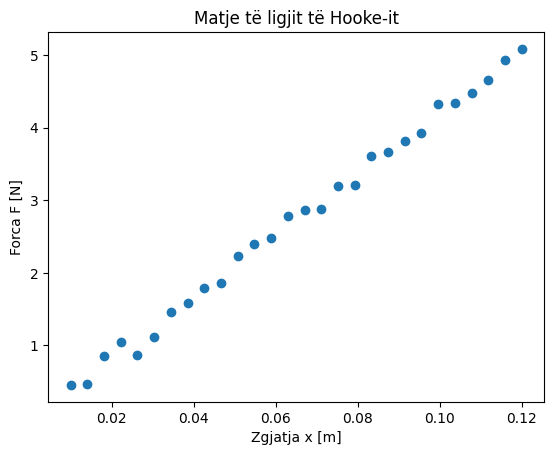

In [2]:
# Qëllimi i këtij blloku: Gjenerimi i matjeve të ligjit të Hooke-it.
x = np.linspace(0.01, 0.12, 28)              # m
k_true = 42.0                                 # N/m
# Gjenerojmë të dhëna të kontrolluara që na lejojnë të dimë strukturën që duhet të zbulojë modeli.
F = k_true*x + rng.normal(0, 0.12, len(x))    # N

# Ndërtojmë një figurë diagnostike; grafiku është pjesë e analizës, jo dekorim.
fig, ax = plt.subplots()
ax.scatter(x, F)
ax.set_xlabel("Zgjatja x [m]")
ax.set_ylabel("Forca F [N]")
ax.set_title("Matje të ligjit të Hooke-it")
plt.show()

**Pyetje për interpretim.** Çfarë përfundimi lejon ky rezultat dhe çfarë **nuk** lejon të përfundojmë? Nëse do të ndryshonim zhurmën, madhësinë e kampionit ose ndarjen e të dhënave, cilën pjesë të rezultatit prisni të ishte më e ndjeshme?

# 2. Zbatim nga parimet e para — CORE

### Para se të ekzekutojmë: Zgjidhja me katrorët më të vegjël

Matrica e projektimit përmban vetëm zgjatjen sepse vendosim hipotezën fizike $F(0)=0$. `np.linalg.lstsq` zgjidh problemin pa formuar inversin në mënyrë eksplicite, gjë që është numerikisht më e qëndrueshme. Ky është një shembull i mirë ku formula analitike dhe implementimi profesional nuk janë identike në formë, por zgjidhin të njëjtin problem.

**Çfarë duhet të vëzhgojmë?** Pas ekzekutimit, kontrolloni jo vetëm vlerën numerike, por edhe nëse drejtimi i ndryshimit, shkalla e madhësive dhe forma e grafikut janë në përputhje me pritshmërinë teorike. Kjo e kthen qelizën nga një komandë programimi në një hap të arsyetimit shkencor.

In [3]:
# Qëllimi i këtij blloku: Zgjidhja me katrorët më të vegjël.
A = x[:, None]  # pa intercept, sepse fizikisht F(0)=0
# Zgjidhim problemin e katrorëve më të vegjël pa formuar inversin në mënyrë eksplicite.
k_hat, *_ = np.linalg.lstsq(A, F, rcond=None)
k_hat = float(k_hat[0])
F_hat = k_hat*x
k_hat

42.06499875552312

### Zbatimi kanonik në `src/`
Për të mos e kopjuar algoritmin në çdo notebook, kursi ruan edhe një zbatim të ripërdorshëm.
Kjo nuk e zëvendëson derivimin e mësipërm; vetëm e paketizon atë në një API të pastër.

### Para se të ekzekutojmë: Moduli kanonik `src`

Pas implementimit transparent, importojmë versionin e ripërdorshëm. Qëllimi është të ndajmë të kuptuarit e algoritmit nga organizimi i kodit: notebook-u shpjegon, ndërsa `src/` siguron një implementim të pastër që mund të përdoret përsëri.

**Çfarë duhet të vëzhgojmë?** Pas ekzekutimit, kontrolloni jo vetëm vlerën numerike, por edhe nëse drejtimi i ndryshimit, shkalla e madhësive dhe forma e grafikut janë në përputhje me pritshmërinë teorike. Kjo e kthen qelizën nga një komandë programimi në një hap të arsyetimit shkencor.

In [4]:
# Qëllimi i këtij blloku: Moduli kanonik `src`.
# Ngarkojmë vetëm mjetet që duhen për këtë hap të analizës.
import sys
# Kërkojmë automatikisht rrënjën e repository-t, në mënyrë që notebook-u të funksionojë nga dosje të ndryshme.
ROOT = Path.cwd()
for candidate in [ROOT, *ROOT.parents]:
    if (candidate / "src").is_dir():
        sys.path.insert(0, str(candidate))
        break
# Ngarkojmë vetëm mjetet që duhen për këtë hap të analizës.
from src.regression.linear import LinearRegressionOLS
# Përshtatim parametrat e modelit mbi bashkësinë e trajnimit.
ols_src = LinearRegressionOLS(fit_intercept=False).fit(x, F)
print("src:", ols_src.coef_[0], "manual:", k_hat)

src: 42.06499875552312 manual: 42.06499875552312


**Pyetje për interpretim.** Çfarë përfundimi lejon ky rezultat dhe çfarë **nuk** lejon të përfundojmë? Nëse do të ndryshonim zhurmën, madhësinë e kampionit ose ndarjen e të dhënave, cilën pjesë të rezultatit prisni të ishte më e ndjeshme?

### Para se të ekzekutojmë: Vija e përshtatjes

Grafiku mbivendos matjet dhe modelin. Nuk mjafton të thuhet se vija “duket mirë”; pjerrësia duhet interpretuar si $k$ dhe përhapja e pikave si kombinim i zhurmës dhe çdo efekti të pambuluar nga modeli.

**Çfarë duhet të vëzhgojmë?** Pas ekzekutimit, kontrolloni jo vetëm vlerën numerike, por edhe nëse drejtimi i ndryshimit, shkalla e madhësive dhe forma e grafikut janë në përputhje me pritshmërinë teorike. Kjo e kthen qelizën nga një komandë programimi në një hap të arsyetimit shkencor.

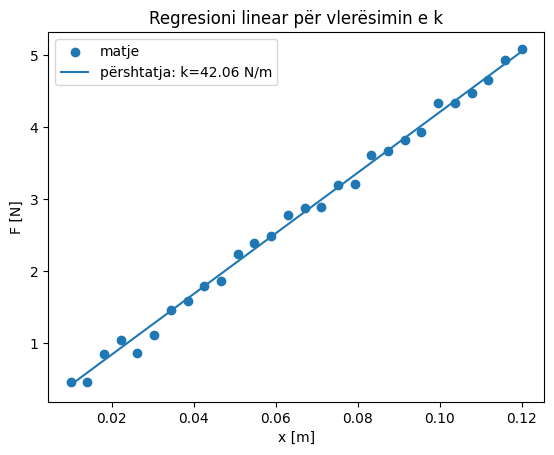

In [5]:
# Qëllimi i këtij blloku: Vija e përshtatjes.
# Ndërtojmë një figurë diagnostike; grafiku është pjesë e analizës, jo dekorim.
fig, ax = plt.subplots()
ax.scatter(x, F, label="matje")
ax.plot(x, F_hat, label=f"përshtatja: k={k_hat:.2f} N/m")
ax.set_xlabel("x [m]"); ax.set_ylabel("F [N]")
ax.legend(); ax.set_title("Regresioni linear për vlerësimin e k")
plt.show()

**Pyetje për interpretim.** Çfarë përfundimi lejon ky rezultat dhe çfarë **nuk** lejon të përfundojmë? Nëse do të ndryshonim zhurmën, madhësinë e kampionit ose ndarjen e të dhënave, cilën pjesë të rezultatit prisni të ishte më e ndjeshme?

**Interpretim.** Pjerrësia e vijës është vetë parametri fizik $k$. Regresioni linear këtu nuk është thjesht një algoritëm parashikimi: është një procedurë vlerësimi parametrash.

Në një analizë reale ky interpretim duhet të shoqërohet me kontroll të njësive, madhësive karakteristike dhe hipotezave që lejojnë kalimin nga një tregues numerik te një përfundim fizik.

# 3. Residualet dhe cilësia e modelit — CORE

### Para se të ekzekutojmë: Residualet kundrejt madhësisë së pavarur

Residualet janë testi i parë i hipotezës së modelit. Nëse shfaqin lakim, prirje ose ndryshim sistematik të amplitudës me $x$, kemi arsye të dyshojmë për jolinearitet, heteroskedasticitet ose fizikë shtesë.

**Çfarë duhet të vëzhgojmë?** Pas ekzekutimit, kontrolloni jo vetëm vlerën numerike, por edhe nëse drejtimi i ndryshimit, shkalla e madhësive dhe forma e grafikut janë në përputhje me pritshmërinë teorike. Kjo e kthen qelizën nga një komandë programimi në një hap të arsyetimit shkencor.

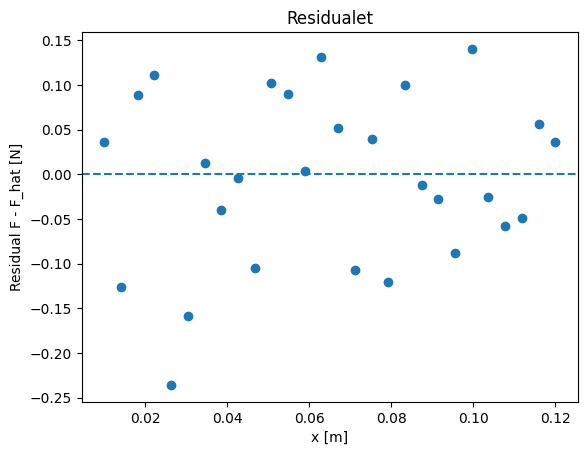

In [6]:
# Qëllimi i këtij blloku: Residualet kundrejt madhësisë së pavarur.
res = F - F_hat
# Ndërtojmë një figurë diagnostike; grafiku është pjesë e analizës, jo dekorim.
fig, ax = plt.subplots()
ax.scatter(x, res)
ax.axhline(0, linestyle="--")
ax.set_xlabel("x [m]"); ax.set_ylabel("Residual F - F_hat [N]")
ax.set_title("Residualet")
plt.show()

**Pyetje për interpretim.** Çfarë përfundimi lejon ky rezultat dhe çfarë **nuk** lejon të përfundojmë? Nëse do të ndryshonim zhurmën, madhësinë e kampionit ose ndarjen e të dhënave, cilën pjesë të rezultatit prisni të ishte më e ndjeshme?

### Para se të ekzekutojmë: Shpërndarja e residualeve

Histogrami ndihmon të kontrollojmë nëse residualet janë afërsisht simetrike dhe pa bishta ekstremë. Normaliteti nuk është kërkesë për çdo përdorim të OLS, por bëhet i rëndësishëm kur ndërtojmë intervale besimi dhe inferencë statistikore klasike.

**Çfarë duhet të vëzhgojmë?** Pas ekzekutimit, kontrolloni jo vetëm vlerën numerike, por edhe nëse drejtimi i ndryshimit, shkalla e madhësive dhe forma e grafikut janë në përputhje me pritshmërinë teorike. Kjo e kthen qelizën nga një komandë programimi në një hap të arsyetimit shkencor.

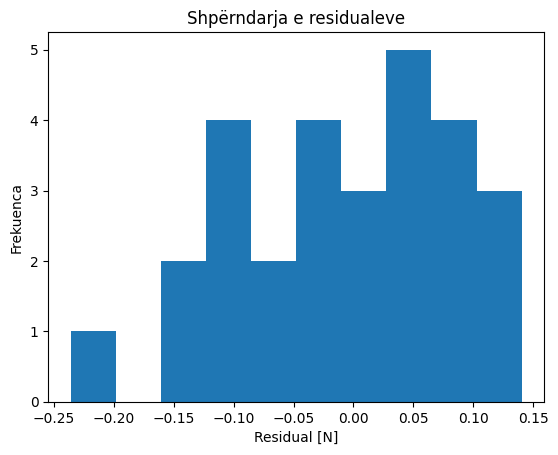

In [7]:
# Qëllimi i këtij blloku: Shpërndarja e residualeve.
# Ndërtojmë një figurë diagnostike; grafiku është pjesë e analizës, jo dekorim.
fig, ax = plt.subplots()
ax.hist(res, bins=10)
ax.set_xlabel("Residual [N]"); ax.set_ylabel("Frekuenca")
ax.set_title("Shpërndarja e residualeve")
plt.show()

**Pyetje për interpretim.** Çfarë përfundimi lejon ky rezultat dhe çfarë **nuk** lejon të përfundojmë? Nëse do të ndryshonim zhurmën, madhësinë e kampionit ose ndarjen e të dhënave, cilën pjesë të rezultatit prisni të ishte më e ndjeshme?

**Interpretim.** Residualet duhet të jenë pa strukturë sistematike nëse modeli linear është i përshtatshëm. Një lakim i qartë do të sinjalizonte fizikë të munguar, jo thjesht 'gabim të modelit'.

Në një analizë reale ky interpretim duhet të shoqërohet me kontroll të njësive, madhësive karakteristike dhe hipotezave që lejojnë kalimin nga një tregues numerik te një përfundim fizik.

# 4. Pasiguria e parametrit — CORE

Në modelin me një parametër dhe zhurmë homoskedastike, një vlerësim i variancës së zhurmës është
$$
s^2=\frac{\sum_i r_i^2}{n-p},
$$
ndërsa matrica e kovariancës së parametrave është
$$
\mathrm{Cov}(\hat\beta)=s^2(X^TX)^{-1}.
$$

### Para se të ekzekutojmë: Pacaktueshmëria e parametrit

Këtu kalojmë nga një numër i vetëm te një vlerësim me pacaktueshmëri. Varianca e residualeve përdoret për të vlerësuar kovariancën e parametrave. Në një raport fizik, $k$ pa pacaktueshmëri është informacion i paplotë.

**Çfarë duhet të vëzhgojmë?** Pas ekzekutimit, kontrolloni jo vetëm vlerën numerike, por edhe nëse drejtimi i ndryshimit, shkalla e madhësive dhe forma e grafikut janë në përputhje me pritshmërinë teorike. Kjo e kthen qelizën nga një komandë programimi në një hap të arsyetimit shkencor.

In [8]:
# Qëllimi i këtij blloku: Pacaktueshmëria e parametrit.
n, p = len(F), 1
s2 = np.sum(res**2)/(n-p)
cov_beta = s2*np.linalg.inv(A.T@A)
se_k = np.sqrt(cov_beta[0,0])
print(f"k = {k_hat:.3f} ± {se_k:.3f} N/m (1σ)")

k = 42.065 ± 0.248 N/m (1σ)


**Pyetje për interpretim.** Çfarë përfundimi lejon ky rezultat dhe çfarë **nuk** lejon të përfundojmë? Nëse do të ndryshonim zhurmën, madhësinë e kampionit ose ndarjen e të dhënave, cilën pjesë të rezultatit prisni të ishte më e ndjeshme?

# 5. Krahasimi me scikit-learn — CORE

### Para se të ekzekutojmë: Krahasimi me bibliotekën

`LinearRegression` duhet të japë të njëjtin rezultat numerik me implementimin manual kur hipotezat dhe parametrizimi janë të njëjta. Ky krahasim është një kontroll i dobishëm i kodit tonë dhe një shembull i filozofisë first-principles → library → comparison.

**Çfarë duhet të vëzhgojmë?** Pas ekzekutimit, kontrolloni jo vetëm vlerën numerike, por edhe nëse drejtimi i ndryshimit, shkalla e madhësive dhe forma e grafikut janë në përputhje me pritshmërinë teorike. Kjo e kthen qelizën nga një komandë programimi në një hap të arsyetimit shkencor.

In [9]:
# Qëllimi i këtij blloku: Krahasimi me bibliotekën.
# Ngarkojmë vetëm mjetet që duhen për këtë hap të analizës.
from sklearn.linear_model import LinearRegression
# Përshtatim parametrat e modelit mbi bashkësinë e trajnimit.
model = LinearRegression(fit_intercept=False).fit(x[:,None], F)
print(model.coef_[0], k_hat, model.coef_[0]-k_hat)

42.06499875552312 42.06499875552312 0.0


**Pyetje për interpretim.** Çfarë përfundimi lejon ky rezultat dhe çfarë **nuk** lejon të përfundojmë? Nëse do të ndryshonim zhurmën, madhësinë e kampionit ose ndarjen e të dhënave, cilën pjesë të rezultatit prisni të ishte më e ndjeshme?

### Para se të ekzekutojmë: Ndikimi i zhurmës

Përsërisim eksperimentin shumë herë për nivele të ndryshme zhurme. Kjo e zhvendos vëmendjen nga një realizim i vetëm te sjellja statistikore e estimatorit. Presim që shpërndarja e gabimit të $k$ të zgjerohet me rritjen e zhurmës.

**Çfarë duhet të vëzhgojmë?** Pas ekzekutimit, kontrolloni jo vetëm vlerën numerike, por edhe nëse drejtimi i ndryshimit, shkalla e madhësive dhe forma e grafikut janë në përputhje me pritshmërinë teorike. Kjo e kthen qelizën nga një komandë programimi në një hap të arsyetimit shkencor.

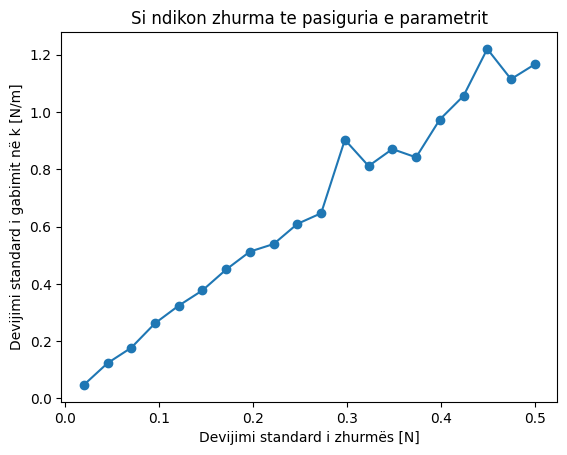

In [10]:
# Qëllimi i këtij blloku: Ndikimi i zhurmës.
noise_levels = np.linspace(0.02, 0.5, 20)
errors = []
for sigma in noise_levels:
    vals=[]
    # Përsërisim procedurën për të studiuar konvergjencën ose ndjeshmërinë ndaj parametrave.
    for _ in range(80):
        # Gjenerojmë të dhëna të kontrolluara që na lejojnë të dimë strukturën që duhet të zbulojë modeli.
        Fsim = k_true*x + rng.normal(0, sigma, len(x))
        # Zgjidhim problemin e katrorëve më të vegjël pa formuar inversin në mënyrë eksplicite.
        kval = np.linalg.lstsq(A, Fsim, rcond=None)[0][0]
        vals.append(kval-k_true)
    errors.append(np.std(vals))
# Ndërtojmë një figurë diagnostike; grafiku është pjesë e analizës, jo dekorim.
fig, ax = plt.subplots()
ax.plot(noise_levels, errors, marker="o")
ax.set_xlabel("Devijimi standard i zhurmës [N]")
ax.set_ylabel("Devijimi standard i gabimit në k [N/m]")
ax.set_title("Si ndikon zhurma te pasiguria e parametrit")
plt.show()

**Pyetje për interpretim.** Çfarë përfundimi lejon ky rezultat dhe çfarë **nuk** lejon të përfundojmë? Nëse do të ndryshonim zhurmën, madhësinë e kampionit ose ndarjen e të dhënave, cilën pjesë të rezultatit prisni të ishte më e ndjeshme?

---
## Deri këtu: materiali bazë për orën mësimore

Në një seancë rreth 60 minuta, zakonisht ndalemi këtu. Seksionet që vijojnë janë për thellim,
ushtrime të pavarura dhe eksperimentim.

# 6. Shembull i dytë: rënia e lirë — EXTENDED

Nga $s(t)=s_0+v_0t+\frac12gt^2$, nëse $s_0$ dhe $v_0$ njihen, vlerësimi i $g$ bëhet përsëri
regresion linear ndaj veçorisë $t^2/2$.

### Para se të ekzekutojmë: Rënia e lirë si regresion linear në një veçori të transformuar

Edhe një marrëdhënie jo-lineare në kohë mund të jetë lineare në parametrat që duam të vlerësojmë. Duke përdorur $t^2/2$ si veçori, vlerësimi i $g$ bëhet problem linear. Kjo tregon rëndësinë e zgjedhjes së përfaqësimit.

**Çfarë duhet të vëzhgojmë?** Pas ekzekutimit, kontrolloni jo vetëm vlerën numerike, por edhe nëse drejtimi i ndryshimit, shkalla e madhësive dhe forma e grafikut janë në përputhje me pritshmërinë teorike. Kjo e kthen qelizën nga një komandë programimi në një hap të arsyetimit shkencor.

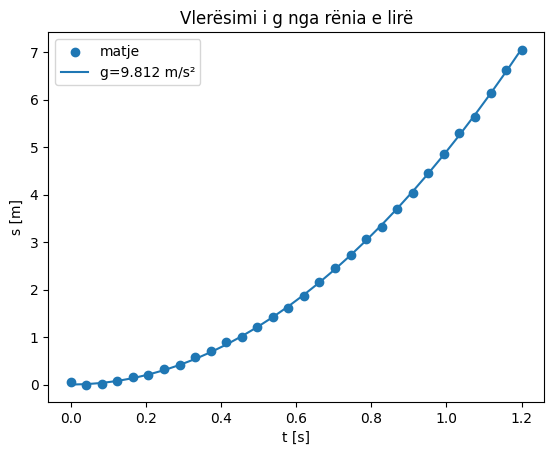

In [11]:
# Qëllimi i këtij blloku: Rënia e lirë si regresion linear në një veçori të transformuar.
t = np.linspace(0, 1.2, 30)
g_true = 9.81
# Gjenerojmë të dhëna të kontrolluara që na lejojnë të dimë strukturën që duhet të zbulojë modeli.
s = 0.5*g_true*t**2 + rng.normal(0, 0.03, len(t))
phi = 0.5*t**2
# Zgjidhim problemin e katrorëve më të vegjël pa formuar inversin në mënyrë eksplicite.
g_hat = np.linalg.lstsq(phi[:,None], s, rcond=None)[0][0]

# Ndërtojmë një figurë diagnostike; grafiku është pjesë e analizës, jo dekorim.
fig, ax = plt.subplots()
ax.scatter(t, s, label="matje")
ax.plot(t, 0.5*g_hat*t**2, label=f"g={g_hat:.3f} m/s²")
ax.set_xlabel("t [s]"); ax.set_ylabel("s [m]")
ax.legend(); ax.set_title("Vlerësimi i g nga rënia e lirë")
plt.show()

**Pyetje për interpretim.** Çfarë përfundimi lejon ky rezultat dhe çfarë **nuk** lejon të përfundojmë? Nëse do të ndryshonim zhurmën, madhësinë e kampionit ose ndarjen e të dhënave, cilën pjesë të rezultatit prisni të ishte më e ndjeshme?

# 7. Kondicionimi numerik — EXTENDED

### Para se të ekzekutojmë: Kondicionimi numerik

Dy veçori pothuajse kolineare e bëjnë problemin të paqëndrueshëm. `cond(X^TX)` mat se sa mund të amplifikohen perturbimet numerike dhe zhurma te koeficientët. Ky është një motivim i drejtpërdrejtë për regularizimin që do të vijë në notebook-un pasues.

**Çfarë duhet të vëzhgojmë?** Pas ekzekutimit, kontrolloni jo vetëm vlerën numerike, por edhe nëse drejtimi i ndryshimit, shkalla e madhësive dhe forma e grafikut janë në përputhje me pritshmërinë teorike. Kjo e kthen qelizën nga një komandë programimi në një hap të arsyetimit shkencor.

In [12]:
# Qëllimi i këtij blloku: Kondicionimi numerik.
# Dy veçori pothuajse kolineare
u = np.linspace(0, 1, 80)
# Gjenerojmë të dhëna të kontrolluara që na lejojnë të dimë strukturën që duhet të zbulojë modeli.
Xc = np.c_[u, u + 1e-5*rng.normal(size=len(u))]
cond = np.linalg.cond(Xc.T@Xc)
cond

np.float64(11981502199.74479)

**Interpretim.** Kur veçoritë janë pothuajse linearisht të varura, $X^TX$ bëhet keq e kondicionuar dhe koeficientët mund të jenë shumë të paqëndrueshëm edhe kur parashikimet duken të mira.

Në një analizë reale ky interpretim duhet të shoqërohet me kontroll të njësive, madhësive karakteristike dhe hipotezave që lejojnë kalimin nga një tregues numerik te një përfundim fizik.

# Ushtrime — PLAYGROUND

        ## A. Ushtrime të shkurtra
        1. Shtoni intercept dhe diskutoni kuptimin fizik të tij.
2. Dyfishoni numrin e matjeve dhe vlerësoni si ndryshon $\sigma_k$.
3. Shtoni një outlier dhe krahasojeni $k$ me rastin pa outlier.
4. Përdorni bootstrap për të vlerësuar shpërndarjen e $k$.

        ## B. Ushtrim i plotë
        Simuloni 100 eksperimente Hooke me zhurmë të ndryshme dhe verifikoni numerikisht se pasiguria e vlerësimit bie afërsisht me rritjen e numrit të pikave.

        ## C. Playground
        Ndryshoni diapazonin e zgjatjeve, zhurmën dhe numrin e matjeve.

In [13]:
# TODO / PLAYGROUND
# Ndryshoni parametrat, shtoni grafikë ose krahasoni modele të tjera.

## Përmbledhje konceptuale e kapitullit

Notebook-u **Regresioni linear** duhet të lihet me një ide të qartë: algoritmi është vetëm një hallkë e arsyetimit. Para tij kemi zgjedhjen e përfaqësimit dhe hipotezat mbi të dhënat; pas tij kemi validimin, diagnostikën dhe interpretimin. Nëse një student mund të ekzekutojë të gjitha qelizat por nuk mund të shpjegojë pse secila prej tyre është e nevojshme, atëherë puna llogaritëse nuk është përfunduar ende.

Për studim të mëtejshëm, rikthehuni te shënimet e leksionit për derivimet e plota dhe përdoreni këtë notebook si laborator ku këto ide testohen numerikisht.

### Zgjidhje orientuese për instruktorin
- Intercept-i përfaqëson forcën e matur kur $x=0$; fizikisht mund të sinjalizojë offset të sensorit.
- Pasiguria e pjerrësisë bie afërsisht si $1/\sqrt{N}$ kur shpërndarja e $x$ dhe zhurma mbeten të ngjashme.
- Një outlier mund të ndryshojë dukshëm OLS sepse residualet katrorë peshojnë shumë devijimet e mëdha.
- Bootstrap i pjerrësisë merret duke rimostruar çiftet $(x_i,F_i)$ me zëvendësim.